Что мы смотрели на прошлом занятии:
- как разбивать код на функции:
    - по шагам алгоритма
    - Когда функционал повторяется
- typing

In [ ]:
def do_something() -> None:
    pass

# Функции

1. Параметры, `*args`, `**kwargs`
2. Генераторы
3. Области видимости
4. Функции высшего порядка
5. Безымянные функции
6. Декораторы

# Параметры, `*args`, `**kwargs`

In [ ]:
def do_nothing():  # сигнатура функции
    pass

In [ ]:
def return_value():
    return 42  # Возвращаемое значение


return_value()

In [ ]:
def greet(name, phrase):
    print(phrase.format(name=name))

greet(name="Kris", phrase="Hi, {name}")

In [ ]:
def greet(name, phrase="Hello {name}"):
    print(phrase.format(name=name))

greet("Kris")
greet("Kris", "Hi, {name}")
greet(
    name="Kris",
    phrase="Guten Tag, {name}",
)


In [2]:
# Когда хотим передавать параметры только как именованные переменные
def greet(name, *, phrase="Hello {name}"):
    print(phrase.format(name=name))

greet("Kris")
# greet("Kris", "Hi, {name}")
greet(
    "Kris",
    phrase="Gute Nacht, {name}",
)
greet(
    name="Kris",
    phrase="Guten Tag, {name}",
)

Hello Kris
Gute Nacht, Kris
Guten Tag, Kris


Что если мы не знаем, сколько у нас переменных, но хотим напечатать их все?

In [3]:
def print_all(*args, **kwargs):
    for arg in args:
        print(arg, end=" ")
    for kwarg in kwargs.values():
        print(kwarg, end=" ")
    # print(*args, *kwargs.values())


print_all()
print_all(1, 2, test="5")

1 2 5 

In [4]:
def join_all(*args, **kwargs):
    return *args, *kwargs.values()

join_all(1, 2, test=5)

(1, 2, 5)

# Possible issue 1

Вопрос по коду:
- Что эта функция делает?
- Что (может быть) не так с функцией?

In [5]:
def get_top_three(weights: list[float]) -> list[float]:
    weights.sort(reverse=True)
    return weights[:3]


weights = [180.2, 620.9, 310.4, 95.0]
print(get_top_three(weights))

[620.9, 310.4, 180.2]


Длинный макрдаун для размышлений
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
-----

## Ответ: Функция меняет переданный ей список

In [6]:
def get_top_three(_weights):
    _weights.sort(reverse=True)
    return _weights[:3]


weights = [180.2, 620.9, 310.4, 95.0]
top_3_weights = get_top_three(weights)
print(weights)

[620.9, 310.4, 180.2, 95.0]


## Почему?
Все в питоне является объектом (подводка к ООП).
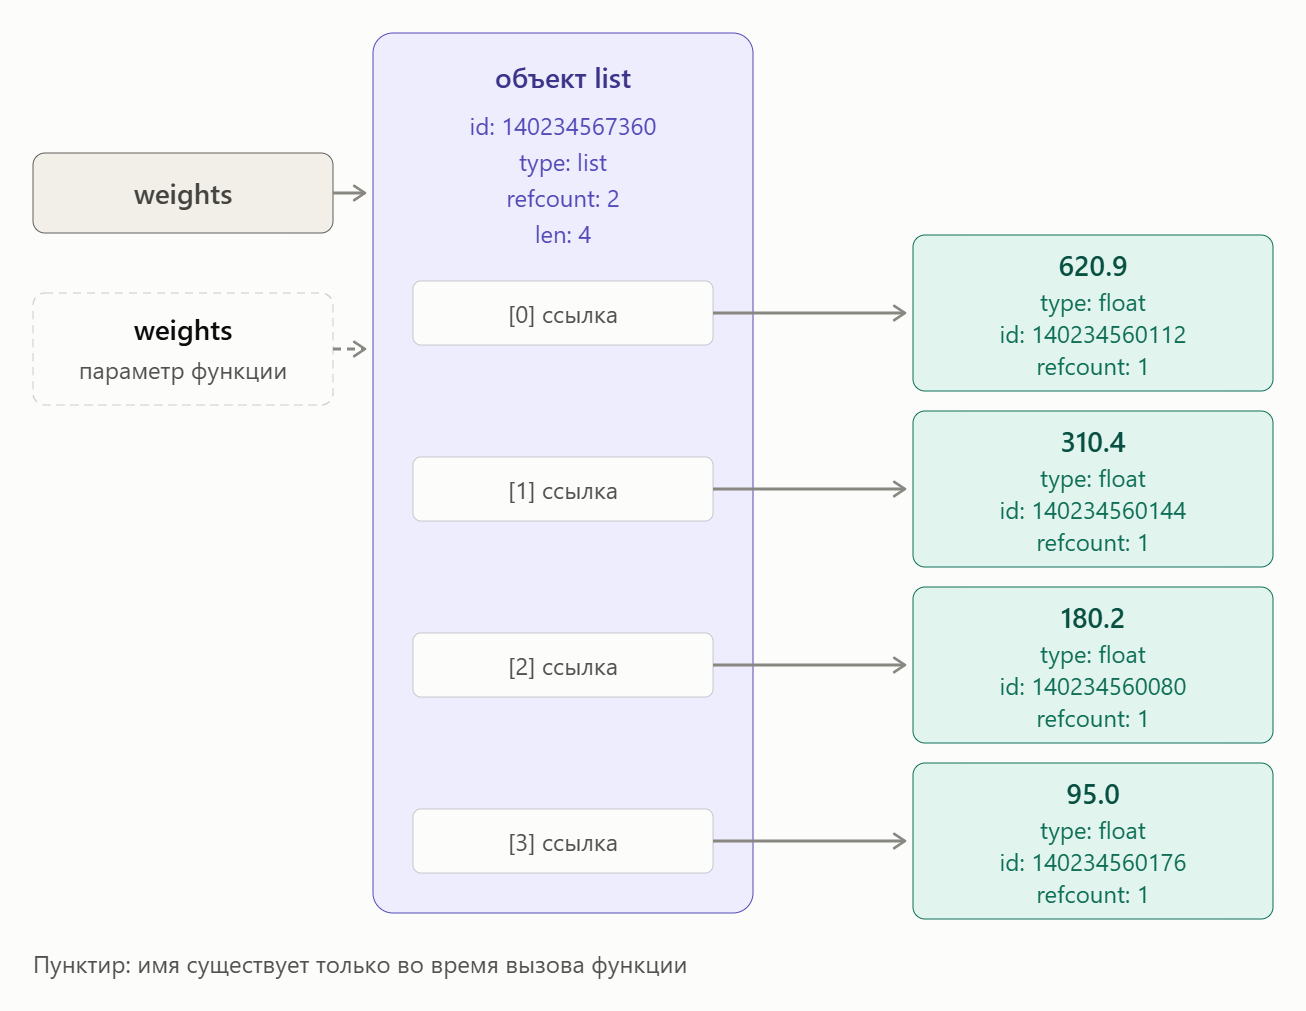
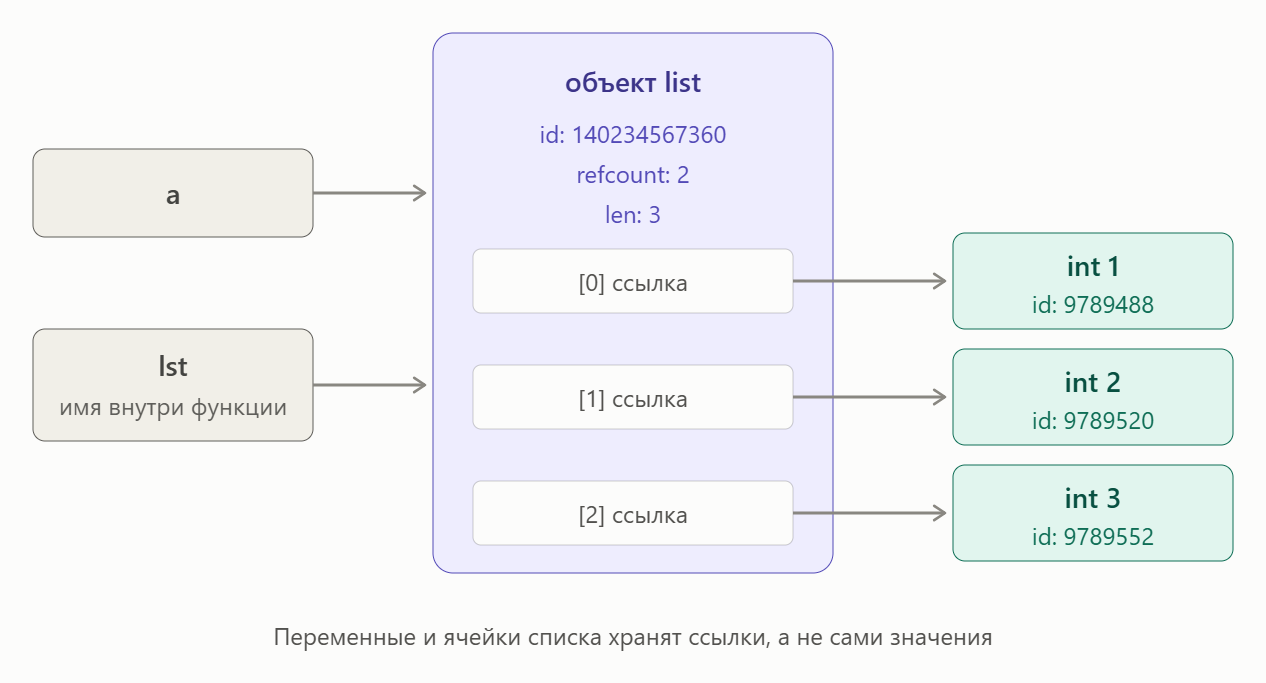

Вопросы:
- Почему это не происходит с типами вроде int \ float?
- Как пофиксить?

In [7]:
def get_top_three(_weights):
    sorted(_weights, reverse=True)
    return _weights[:3]


weights = [180.2, 620.9, 310.4, 95.0]
top_3_weights = get_top_three(weights)
print(weights)

[180.2, 620.9, 310.4, 95.0]


In [8]:
def get_top_three(_weights):
    print(id(_weights))
    _weights = _weights.copy()
    print(id(_weights))
    _weights.sort(reverse=True)
    return _weights[:3]


weights = [180.2, 620.9, 310.4, 95.0]
top_3_weights = get_top_three(weights)
print(weights)

2249662372672
2249662645568
[180.2, 620.9, 310.4, 95.0]


Когда copy не поможет?

In [9]:
def filter_values(_molecules: list[dict]):
    _molecules = _molecules.copy()
    for molecule in _molecules:
        molecule["is_light"] = molecule["molecular_weight"] < 500

    return [molecule for molecule in _molecules if molecule["is_light"]]


molecules = [
    {
        "molecular_weight": 120.0,
        "name": "CCC",
    },
    {
        "molecular_weight": 520.0,
        "name": "CCCCCCCC",
    }
]

print(filter_values(molecules))
print(molecules)


[{'molecular_weight': 120.0, 'name': 'CCC', 'is_light': True}]
[{'molecular_weight': 120.0, 'name': 'CCC', 'is_light': True}, {'molecular_weight': 520.0, 'name': 'CCCCCCCC', 'is_light': False}]


In [10]:
from copy import deepcopy

def filter_values(_molecules: list[dict]):
    _molecules = deepcopy(_molecules)
    for molecule in _molecules:
        molecule["is_light"] = molecule["molecular_weight"] < 500

    return [molecule for molecule in _molecules if molecule["is_light"]]


molecules = [
    {
        "molecular_weight": 120.0,
        "name": "CCC",
    },
    {
        "molecular_weight": 520.0,
        "name": "CCCCCCCC",
    }
]

print(filter_values(molecules))
print(molecules)


[{'molecular_weight': 120.0, 'name': 'CCC', 'is_light': True}]
[{'molecular_weight': 120.0, 'name': 'CCC'}, {'molecular_weight': 520.0, 'name': 'CCCCCCCC'}]


# Possible issue 2
Вопросы:
- Что делает этого код?
- Что с ним не так?

In [12]:
def add_item(item, items=[]):
    items.append(item)
    return items


print(add_item("a"))
print(add_item("b", []))
print(add_item("c"))

['a']
['b']
['a', 'c']


Длинный макрдаун для размышлений
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
--
-----

**Проблема.** Значение по умолчанию создаётся один раз, когда выполняется определение функции. Каждый вызов без аргумента работает с той же структурой в памяти

In [ ]:
def add_item(item, items=[]):
    items.append(item)
    return items

print(add_item("a"))
print(add_item("b"))

In [14]:
def add_item(item, items=None):
    if not items:
        items = []
    items.append(item)
    return items

print(add_item("a"))
print(add_item("b"))
print(add_item("a"))

['a']
['b']
['a']


## Похожие кейсы

In [15]:
import time

def stamp(message, when=time.perf_counter()):
    return message, when


first = stamp("first event")
time.sleep(1)
second = stamp("second event")
print(first, second)

('first event', 619601.6832641) ('second event', 619601.6832641)


# Генераторы

`return` завершает функцию и отдаёт одно значение. Если результатов много, их можно собрать в список, но тогда все они лежат в памяти одновременно. `yield` отдаёт значения **по одному**: функция встаёт на паузу и продолжает с того же места, когда попросят следующее значение.

In [16]:
from typing import Generator


def generate_even_values(_max=5) -> Generator[int, int, None]: # что отдаёт yield, что можно передать внутрь через send и что возвращает return.
    current = 0
    while current <= _max:
        yield current
        current += 2

numbers = generate_even_values()
print(numbers)
print(next(numbers))
print(next(numbers))

<generator object generate_even_values at 0x0000020BFAB6D600>
0
2


In [17]:
for number in numbers:  # продолжает с того места, где остановились
    print("получил", number)

try:
    next(numbers)
except StopIteration:
    print("StopIteration: значения закончились")

получил 4
StopIteration: значения закончились


Генератор удобен в 2 кейсах:
  - когда данные читаются или считаются по частям: строки файла, молекулы из большой базы, файлы из S3
  - значение рассчитывается каждый раз из предыдуших (например, по формуле Фибоначчи)

In [19]:
import csv
import io

text = "mol_id,smiles\nM001,CCO\nM002,c1ccccc1\n"
rows = csv.DictReader(io.StringIO(text))
ids = [row["mol_id"] for row in rows]
text = "mol_id,smiles\nM001,CCO\nM002,c1ccccc1\n"
rows = csv.DictReader(io.StringIO(text))
smiles = [row["smiles"] for row in rows]
print(ids, smiles)

['M001', 'M002'] ['CCO', 'c1ccccc1']


Генераторные выражения

In [20]:
molecules = [
    {
        "molecular_weight": 120,
        "id": "C01",
    },
    {
        "molecular_weight": 510,
        "id": "C02",
    },
    {
        "molecular_weight": 200,
        "id": "C03",
    }
]

# list comprehension
light_molecule_weights = [
    molecule["molecular_weight"]
    for molecule in molecules
    if molecule["molecular_weight"] <= 500
]

min_weight = min(light_molecule_weights)
max_weight = max(light_molecule_weights)
print(min_weight, max_weight)

120 200


In [21]:
# tuple comprehension?
light_molecule_weights = (
    molecule["molecular_weight"]
    for molecule in molecules
    if molecule["molecular_weight"] <= 500
)

min_weight = min(light_molecule_weights)
max_weight = max(light_molecule_weights)
print(min_weight, max_weight)

ValueError: max() iterable argument is empty

Опциональное домашнее задание: работа с генераторами.

На одном из этапов ETL пайплайна мы читаем xml файлы в папке source. парсим поле experiment_date в них и копируем их в папки формата "data_year_month" на основании полученного значения. Ваша задача - написать валидатор работы этого этапа.

На вход принимаются 2 параметра: source_folder, в которой были все файлы до процессинга и destination_folders - список папок, в которые данные были скопированы. Процесс считается успешным, если для каждого файла из source_folder нашелся хотя бы один файл в одном из destination_folder с таким же именем и совпадающей md5 суммой.

Напишите скрипт, который выводит статистику по процессу копирования:
- Сколько файлов из source_folder было просканировано
- Сколько файлов не нашлось ни в одном из destination_folders, а также их названия
- У скольких файлов отличается md5 hash, а также их названия

Предполагается, что все названия уникальные, поэтому коллизия имен (2 одинаковых файла в разных destination_folders) невозможна (можете обработать и этот кейс, но это задание со звездочкой)


# Важный кусок который никуда не влез по логике

Функию можно создать внутри функции

In [ ]:
def process(data):
    # определяем функцию внутри другой функции - может быть полезно когда мы хотим чтобы мелкий кусок логики лежал рядом с его вызовом
    def _filter_even(_data):
        return [number for number in _data if number % 2]

    filtered_data = _filter_even(data)
    return filtered_data

process([1, 2, 3, 4])

# Области видимости

## Вопрос: какие переменные мы можем читать внутри функций?
- Внутри функции outer?
- Внутри функции inner?

In [ ]:
a = "a"


def outer(c):
    b = "b"

    def inner(d):
        e = "e"
        ...
    ...

outer(1)

# место на подумать
--

--

--

--

--

--

In [24]:
a = "a" # global


def outer(c):
    b = "b" # enclosing for inner, local for outer

    def inner(d):
        e = "e" # local
        print(a, b, c, d, e) # print - built-in

    print(a, b, c)
    inner("d")

outer("c")

a b c
a b c d e


<img src="https://images.openai.com/static-rsc-4/o0fT98Bu9cdnsvWLSjiR-bPjhU6qLPv5lvGYpIGXnhqgpRJdKr1cq69klEKXSjeQ_6qKnh0mxclD5UFY6le2-FP8DdtKoY47h5yl6Ab-Rzyxw5YDvuOPxfG-e0zqiDfKbS8ixjKmY0Bo7tLRHflzUCh6BFIvYLdsd-YFSc25mk4Caa_QDyBPfUIfZF4RNEOd?purpose=fullsize">

# Изменяем значения переменных

In [25]:
counter = 0


def increment():
    counter = counter + 1


increment()

UnboundLocalError: cannot access local variable 'counter' where it is not associated with a value

In [26]:
counter = 0


def increment():
    global counter
    counter += 1


increment()
increment()
print(counter)

2


## Никогда не используем
**Почему это антипаттерн**

- по сигнатуре `increment()` не видно, что функция читает и меняет переменную модуля: связь скрыта;
- результат зависит от того, кто и в каком порядке вызывал функции раньше;
- такую функцию трудно тестировать: перед каждым тестом нужно восстанавливать глобальное состояние;
- два независимых счётчика с одной такой функцией не сделать.

In [ ]:
counter = 0


def increment(_counter):
    return _counter + 1


counter = increment(counter)
print(counter)

#### Похожая ситуация с функциями в функциях

In [27]:
def make_counter():
    count = 0

    def increment():
        nonlocal count
        count += 1
        return count

    return increment


counter_a = make_counter()
counter_b = make_counter()

print(counter_a())
print(counter_b())
print(counter_b())


1
1
2


# Функции как объекты высшего порядка

Функции - тоже объекты. Функцию можно положить в переменную, в список или словарь, передать и вернуть, как число или строку. Скобки означают вызов, имя без скобок означает сам объект функции.

In [28]:
print(id(print))
print(type(print))
print(dir(print))

2249579171808
<class 'builtin_function_or_method'>
['__call__', '__class__', '__delattr__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__name__', '__ne__', '__new__', '__qualname__', '__reduce__', '__reduce_ex__', '__repr__', '__self__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__text_signature__']


In [29]:
def execute(func, *args):
    return func(args)

execute(print, 1, 2, 3)
print(execute(max, 1, 2, 3))
print(execute(sum, 1, 2, 3))

(1, 2, 3)
3
6


In [30]:
def make_exclaimer():
    def exclaim(text):
        return text + "!"

    return exclaim


exclaim = make_exclaimer()
print(exclaim("hi"))

hi!


In [32]:
def shout(text):
    return text.upper() + "!"


yell = shout  # второе имя для того же объекта (скобок нет, это не вызов)
print(yell("hi") == "HI!" and yell is shout)

handlers = {
    "loud": shout,
    "plain": str,
}  # функции как значения словаря

handlers.get("loud", print)("1")

True


'1!'

## Полезные функции высшего порядка в Python

Функцию принимают `sorted`, `min`, `max` (параметр `key=`), `map`, `filter`, `functools.reduce`. `any` и `all` удобно сочетать с генераторным выражением.

Знакомый пример: параметр `key=` у `sorted`, `min`, `max` принимает функцию, которая из элемента получает значение для сравнения.

In [33]:
print(sorted(["gamma", "alpha", "be"]))
print(sorted(["gamma", "alpha", "be"], key=len))


['alpha', 'be', 'gamma']
['be', 'gamma', 'alpha']


In [35]:
def get_weight(molecule):
    return molecule["molecular_weight"]

molecules = [
    {
        "molecular_weight": 120,
        "id": "C01",
    },
    {
        "molecular_weight": 510,
        "id": "C02",
    },
    {
        "molecular_weight": 200,
        "id": "C03",
    }
]

print(max(molecules, key=get_weight))

{'molecular_weight': 510, 'id': 'C02'}


## Lambda functions

Функция `get_weight` понадобилась один раз, ради `key=`. Выглядит сомнительно

In [ ]:
molecules = [
    {
        "molecular_weight": 120,
        "id": "C01",
    },
    {
        "molecular_weight": 510,
        "id": "C02",
    },
    {
        "molecular_weight": 200,
        "id": "C03",
    }
]

print(max(molecules, key=lambda molecule: molecule["molecular_weight"]))

Lambda green flags:
- Функция нужна один раз, прямо на месте
- Это одно выражение без if/for/try блоков
- Её передают аргументом: key=, sorted, min/max, map, filter, defaultdict
- Читается сразу, без пояснений

Lambda red flags:
- Присваивание переменной: f = lambda x: ...
- Нужно несколько строк логики, циклы, try/except
- Нужны docstring, аннотации типов, понятное имя в traceback
- Функцию будут переиспользовать или тестировать отдельно
- Выражение длинное или с вложенными тернарниками

## Possible issues 3
- Что делает этот код?
- Что может пойти не так?

In [36]:
checks = [
    lambda value: value > limit
    for limit in (100, 200, 300)
]
check_passes = [
    check(250)
    for check in checks
]

print(check_passes)

[False, False, False]


# Место на подумать
--

--

--

--

--

--

--

## Позднее связывание в лямбдах и замыканиях

**Проблема.** Замыкание хранит ссылку на переменную, а не её значение на момент создания.

In [ ]:
checks = [
    lambda value: value > limit,
    lambda value: value > limit,
    lambda value: value > limit,
]

limit = 300

In [37]:
# checks = [
#     lambda value, limit=100: value > limit,
#     lambda value, limit=200: value > limit,
#     lambda value, limit=300: value > limit,
# ]

checks = [
    lambda value, limit=limit: value > limit
    for limit in (100, 200, 300)
]
check_passes = [check(250) for check in checks]
print(check_passes)

[True, True, False]


In [ ]:
checks = [
    lambda value: value > 100,
    lambda value: value > 200,
    lambda value: value > 300,
]

check_passes = [check(250) for check in checks]
print(check_passes)

In [38]:
value = 250
check_passes = [
    value > threshold
    for threshold in (100, 200, 300)
]

print(check_passes)

[True, True, False]


# Декораторы

Декоратор это функция, которая принимает функцию и возвращает другую, добавляя поведение вокруг вызова.

In [ ]:
def outer(func):
    def inner(*args, **kwargs):
        return func(*args, **kwargs)

    return inner

In [44]:
def log_call(func):
    def inner(*args, **kwargs):
        print(f"DEBUG: function {func.__name__} called with params {args}, {kwargs}")
        result = func(*args, **kwargs)
        print(f"DEBUG: result: {result}")
        return result

    return inner

@log_call
@log_call
@log_call
@log_call
def sum(a, b):
    """Returns the sum of two numbers."""
    return a + b

sum(1, 2)

DEBUG: function inner called with params (1, 2), {}
DEBUG: function inner called with params (1, 2), {}
DEBUG: function inner called with params (1, 2), {}
DEBUG: function sum called with params (1, 2), {}
DEBUG: result: 3
DEBUG: result: 3
DEBUG: result: 3
DEBUG: result: 3


3

In [45]:
# Проблема:

@log_call
def sum(a, b):
    """Returns the sum of two numbers."""
    return a + b

print(sum.__name__)
print(sum.__doc__)

inner
None


In [46]:
from functools import wraps

def log_call(func):
    @wraps(func)
    def inner(*args, **kwargs):
        print(f"debug: function {func.__name__} called with params {args}, {kwargs}")
        result = func(*args, **kwargs)
        print(f"debug: result: {result}")
        return result

    return inner


@log_call
def sum(a, b):
    """Returns the sum of two numbers."""
    return a + b

print(sum.__name__)
print(sum.__doc__)

sum
Returns the sum of two numbers.


# Задание: Напишите декоратор time_it, который будет отмерять время, за которое выполнилась функция

## Маркдаун на подумать
--

--

--

--

--

--

--

--

--

--



## Декоратор с параметрами


In [49]:
def retry(attempts=3, delay=2):
    def outer(func):
        @wraps(func)
        def inner(*args, **kwargs):
            for i in range(attempts):
                try:
                    return func(*args, **kwargs)
                except Exception as e:
                    print(f"Failure: {e}, trying again in {delay} seconds")
                    time.sleep(delay)
            print("No more attempts")
            raise Exception("no more attempts")
        return inner
    return outer
                    

In [50]:
@retry()
def always_fail():
    raise Exception("Wouldn't work")

always_fail()

Failure: Wouldn't work, trying again in 2 seconds
Failure: Wouldn't work, trying again in 2 seconds
Failure: Wouldn't work, trying again in 2 seconds
No more attempts


Exception: no more attempts

In [55]:
import random

@retry(5, 1)
def sometimes_fail():
    if random.randint(0, 1):
        raise Exception("Bad luck")
    print("Success")

sometimes_fail()

Failure: Bad luck, trying again in 1 seconds
Failure: Bad luck, trying again in 1 seconds
Failure: Bad luck, trying again in 1 seconds
Success


# Когда использовать декораторы
- когда надо добавить одинаковое поведение во все функции, по возможности минимально их изменяя
- Когда надо собрать объекты вместе в один список \ слова

In [ ]:
def draw_scatter_plot(data, folder) -> None:
    pass


def draw_crc_curve(data, folder) -> None:
    pass


def draw_graph(data, folder) -> None:
    pass


def write_exception_report(data, folder) -> None:
    pass

In [ ]:
def prepare_data_for_andrew(data, folder) -> None:
    draw_scatter_plot(data, folder)
    draw_crc_curve(data, folder)
    draw_graph(data, folder)
    write_exception_report(data, folder)


def prepare_data_for_kris(data, folder) -> None:
    write_exception_report(data, folder)


def prepare_data_for_ivan(data, folder) -> None:
    draw_scatter_plot(data, folder)
    draw_crc_curve(data, folder)

Работает, но выглядит стремно;
- непонятно, что из функций еще используется
- люди опредея.


In [56]:
from collections import defaultdict
from typing import Callable

REPORTS: dict[str, list[Callable]] = defaultdict(list)


def for_people(*names: str):
    def decorator(func: Callable) -> Callable:
        for name in names:
            REPORTS[name].append(func)
        return func
    return decorator


@for_people("andrew", "ivan")
def draw_scatter_plot(data, folder) -> None:
    pass


@for_people("andrew", "ivan")
def draw_crc_curve(data, folder) -> None:
    pass


@for_people("andrew")
def draw_graph(data, folder) -> None:
    pass


@for_people("andrew", "kris")
def write_exception_report(data, folder) -> None:
    pass


def prepare_data(person: str, data, folder) -> None:
    if person not in REPORTS:
        raise ValueError(f"Unknown person: {person}")
    for step in REPORTS[person]:
        step(data, folder)


prepare_data("andrew", [], ".")

for name, funcs in REPORTS.items():
    print(name, [func.__name__ for func in funcs])

andrew ['draw_scatter_plot', 'draw_crc_curve', 'draw_graph', 'write_exception_report']
ivan ['draw_scatter_plot', 'draw_crc_curve']
kris ['write_exception_report']
